# Deep reinforcement learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/deep-rl/deep-rl-notebook.ipynb)

Companion notebook for the *Deep reinforcement learning* slides. Each idea is written first by hand
with NumPy and then with the PyTorch tools that do the same job.

**Data:** no data set; the agent moves in the deck's corridor: position $s$ from 0 to 1, each move shifts it by 0.1,
the left end pays +0.5 and the right end +1, $\gamma = 0.8$.

In [1]:
import copy
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.distributions import Categorical

RANDOM_STATE = 42
GAMMA = 0.8
ALPHA = 0.1
LEARNING_RATE = 0.25
BATCH = 32
STEPS = 3000
COPY_EVERY = 50
CAPACITY = 1000

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(RANDOM_STATE)

POSITIONS = np.round(np.arange(1, 10) / 10, 1)  # non-terminal positions 0.1 ... 0.9
LEFT, RIGHT = 0, 1


def step(s, a):
    """The environment: return (reward, next position, done)."""
    s_next = round(s + (0.1 if a == RIGHT else -0.1), 1)
    if s_next <= 0:
        return 0.5, s_next, True
    if s_next >= 1:
        return 1.0, s_next, True
    return 0.0, s_next, False

## 1. A linear Q-function

$Q(s, a; \boldsymbol\theta) = \boldsymbol\theta_a^\top \boldsymbol\phi(s)$, learned with
$\boldsymbol\theta_a \leftarrow \boldsymbol\theta_a + \alpha\,\delta\,\boldsymbol\phi(s)$.
A table is the special case where $\boldsymbol\phi(s)$ marks one state, so both should learn the same numbers.

In [2]:
def one_hot(s):
    return np.eye(len(POSITIONS))[int(round(s * 10)) - 1]


theta = np.zeros((2, len(POSITIONS)))  # one weight vector per action
table = np.zeros((len(POSITIONS), 2))  # Topic 21's Q-table
for _ in range(500):
    s = rng.choice(POSITIONS)
    a = rng.integers(2)
    r, s_next, done = step(s, a)
    i = int(round(s * 10)) - 1  # row of s in the table
    i_next = i + (1 if a == RIGHT else -1)  # row of s'

    if done:
        target = r
    else:
        target = r + GAMMA * (theta @ one_hot(s_next)).max()  # r + gamma max_a' Q(s', a')
    delta = target - theta[a] @ one_hot(s)  # minus Q(s, a)
    theta[a] += ALPHA * delta * one_hot(s)

    if done:
        table_target = r
    else:
        table_target = r + GAMMA * table[i_next].max()
    table_delta = table_target - table[i, a]
    table[i, a] += ALPHA * table_delta

print("same result:", np.allclose(theta.T, table))

same result: True


In PyTorch a linear Q-function is `nn.Linear(features, actions, bias=False)`; its `weight` row $a$ is $\boldsymbol\theta_a$.
The rule above is one gradient step on $\frac{1}{2}\big(y - Q(s, a; \boldsymbol\theta)\big)^2$ with the target $y$ held fixed,
so `torch.optim.SGD` with autograd gives the same update.

In [3]:
q_linear = nn.Linear(len(POSITIONS), 2, bias=False)
with torch.no_grad():
    q_linear.weight.copy_(torch.tensor(theta))
optimizer = torch.optim.SGD(q_linear.parameters(), lr=ALPHA)

s, a = 0.3, RIGHT
r, s_next, done = step(s, a)
target = r + GAMMA * (theta @ one_hot(s_next)).max()  # y = r + gamma max_a' Q(s', a')
delta = target - theta[a] @ one_hot(s)
theta_by_hand = theta.copy()
theta_by_hand[a] += ALPHA * delta * one_hot(s)

with torch.no_grad():
    q_next = q_linear(torch.tensor(one_hot(s_next))).max()  # max_a' Q(s', a')
    y = r + GAMMA * q_next
optimizer.zero_grad()
q = q_linear(torch.tensor(one_hot(s)))[a]  # Q(s, a)
loss = 0.5 * (y - q) ** 2
loss.backward()
optimizer.step()
print("same result:", np.allclose(theta_by_hand, q_linear.weight.detach().numpy()))

same result: True


## 2. The DQN loss and its gradient

A small network (one hidden layer of `tanh` units, one output per action) gives $Q(s, a; \boldsymbol\theta)$.
The loss is $L(\boldsymbol\theta) = \frac{1}{B}\sum_i \big(y_i - Q(s_i, a_i; \boldsymbol\theta)\big)^2$ with the targets
$y_i = r_i + \gamma \max_{a'} Q(s'_i, a'; \boldsymbol\theta^-)$ held fixed. The NumPy class has a `forward` and a
`backward` (backpropagation by hand) and keeps its weights in PyTorch's layout, (outputs, inputs).

In [4]:
class QNetwork:
    """NumPy twin of nn.Sequential(nn.Linear(1, 8), nn.Tanh(), nn.Linear(8, 2))."""
    def __init__(self, hidden: int = 8):
        self.W1 = rng.normal(size=(hidden, 1))
        self.b1 = rng.normal(size=hidden)
        self.W2 = rng.normal(size=(2, hidden))
        self.b2 = np.zeros(2)

    def parameters(self) -> list[np.ndarray]:
        return [self.W1, self.b1, self.W2, self.b2]

    def forward(self, s: np.ndarray) -> np.ndarray:
        self.s = s[:, None]  # one column: a batch of 1-feature inputs
        self.hidden = np.tanh(self.s @ self.W1.T + self.b1)
        q = self.hidden @ self.W2.T + self.b2
        return q

    def backward(self, d_q: np.ndarray) -> list[np.ndarray]:
        """Gradients of the loss for each parameter, given dL/dQ."""
        grad_W2 = d_q.T @ self.hidden
        grad_b2 = d_q.sum(axis=0)
        d_hidden = d_q @ self.W2 * (1 - self.hidden ** 2)  # tanh' = 1 - tanh^2
        grad_W1 = d_hidden.T @ self.s
        grad_b1 = d_hidden.sum(axis=0)
        return [grad_W1, grad_b1, grad_W2, grad_b2]


q_net = QNetwork()
target_net = copy.deepcopy(q_net)  # the frozen copy theta^-

s_b = rng.choice(POSITIONS, BATCH)
a_b = rng.integers(2, size=BATCH)
outcomes = [step(s, a) for s, a in zip(s_b, a_b)]
r_b, next_b, done_b = map(np.array, zip(*outcomes))

q_next = target_net.forward(next_b).max(axis=1)  # max_a' Q(s'_i, a'; theta^-)
y = r_b + GAMMA * q_next * (1 - done_b)  # no future value after the last step

q = q_net.forward(s_b)
rows = np.arange(BATCH)
q_taken = q[rows, a_b]  # Q(s_i, a_i; theta)
loss_by_hand = np.mean((y - q_taken) ** 2)
d_q = np.zeros_like(q)  # dL/dQ is zero for the actions not taken
d_q[rows, a_b] = 2 * (q_taken - y) / BATCH
gradient = q_net.backward(d_q)

In PyTorch: the same `nn.Sequential` with the weights copied in, `copy.deepcopy` for $\boldsymbol\theta^-$, targets under
`torch.no_grad()`, `gather` to pick $Q(s_i, a_i)$, `F.mse_loss` for $L$ and `backward()` for the gradient.
(The DQN paper clips the error, which is `F.smooth_l1_loss`.)

In [5]:
torch_q = nn.Sequential(nn.Linear(1, 8), nn.Tanh(), nn.Linear(8, 2))
with torch.no_grad():
    for p, value in zip(torch_q.parameters(), q_net.parameters()):
        p.copy_(torch.tensor(value))
torch_target = copy.deepcopy(torch_q)

s_t = torch.tensor(s_b)
a_t = torch.tensor(a_b)
r_t = torch.tensor(r_b)
next_t = torch.tensor(next_b)
done_t = torch.tensor(done_b).double()
with torch.no_grad():
    q_next_t = torch_target(next_t.unsqueeze(1)).max(dim=1).values  # max_a' Q(s', a'; theta^-)
    y_t = r_t + GAMMA * q_next_t * (1 - done_t)
q_values = torch_q(s_t.unsqueeze(1))  # Q(s_i, a) for both actions
q_t = q_values.gather(1, a_t.unsqueeze(1)).squeeze(1)  # Q(s_i, a_i)
loss = F.mse_loss(q_t, y_t)
loss.backward()
print(f"loss {loss.item():.3f} | same result:", np.isclose(loss_by_hand, loss.item()))
same_gradient = True
for g, p in zip(gradient, torch_q.parameters()):
    same_gradient = same_gradient and np.allclose(g, p.grad.numpy())
print("same gradient:", same_gradient)

loss 4.509 | same result: True
same gradient: True


The update $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha \nabla_{\boldsymbol\theta} L(\boldsymbol\theta)$ by hand, and with `torch.optim.SGD`.

In [6]:
for p, g in zip(q_net.parameters(), gradient):
    p -= LEARNING_RATE * g
sgd = torch.optim.SGD(torch_q.parameters(), lr=LEARNING_RATE)
sgd.step()
same_parameters = True
for mine, p in zip(q_net.parameters(), torch_q.parameters()):
    same_parameters = same_parameters and np.allclose(mine, p.detach().numpy())
print("same result:", same_parameters)

same result: True


## 3. Training with replay and a target network

As in the deck, a linear $Q$ on 8 bumps $\phi_k(s) = e^{-(s - c_k)^2 / (2 \cdot 0.1^2)}$ learns from random moves.
Each step is stored in a replay buffer $\mathcal{B}$, each update uses a random mini-batch, and the targets come from a
frozen copy $\boldsymbol\theta^-$ that is refreshed every `COPY_EVERY` steps with `load_state_dict`.
The buffer is a small class with `push` and `sample`; when full, the oldest step is dropped.

In [7]:
class ReplayBuffer:
    """Keeps the last `capacity` transitions and samples random mini-batches."""
    def __init__(self, capacity: int):
        self.memory = deque(maxlen=capacity)

    def push(self, *transition) -> None:
        self.memory.append(transition)

    def sample(self, batch_size: int) -> list[torch.Tensor]:
        rows = rng.integers(len(self.memory), size=batch_size)
        transitions = [self.memory[i] for i in rows]
        columns = zip(*transitions)  # (s, a, r, s', done) as five columns
        return [torch.tensor(np.array(column)) for column in columns]


CENTERS = torch.linspace(0, 1, 8)


def bumps(s: torch.Tensor) -> torch.Tensor:
    distance = s.unsqueeze(1) - CENTERS  # s - c_k for every bump k
    return torch.exp(-distance ** 2 / (2 * 0.1 ** 2))


q_bumps = nn.Linear(len(CENTERS), 2, bias=False)
nn.init.zeros_(q_bumps.weight)
q_frozen = copy.deepcopy(q_bumps)
optimizer = torch.optim.SGD(q_bumps.parameters(), lr=LEARNING_RATE)
buffer = ReplayBuffer(CAPACITY)

s = rng.choice(POSITIONS)
for t in range(STEPS):
    if t % COPY_EVERY == 0:
        q_frozen.load_state_dict(q_bumps.state_dict())
    a = rng.integers(2)
    r, s_next, done = step(s, a)
    buffer.push(s, a, r, s_next, done)
    s = rng.choice(POSITIONS) if done else s_next

    s_b, a_b, r_b, next_b, done_b = buffer.sample(BATCH)
    with torch.no_grad():
        q_next = q_frozen(bumps(next_b)).max(dim=1).values  # max_a' Q(s', a'; theta^-)
        y = r_b + GAMMA * q_next * (1 - done_b.double())
    optimizer.zero_grad()
    q_values = q_bumps(bumps(s_b))
    q = q_values.gather(1, a_b.unsqueeze(1)).squeeze(1)  # Q(s, a; theta)
    loss = F.mse_loss(q, y)
    loss.backward()
    optimizer.step()

The exact $Q^*$ comes from value iteration on the nine positions (Topic 20). The network's values are
approximate, so we compare them with a tolerance and check that its greedy action, `argmax`, is the optimal one everywhere.

same values: True
same policy: True


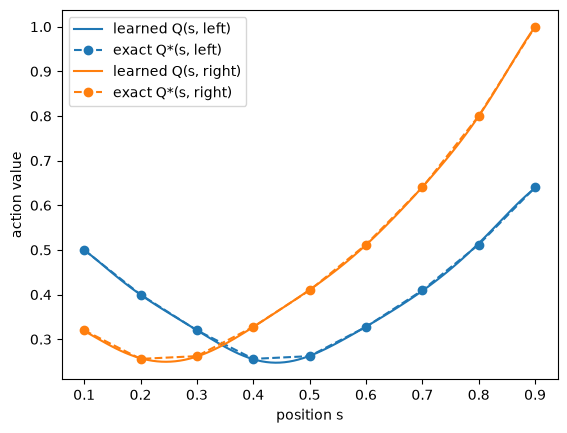

In [8]:
Q_star = np.zeros((len(POSITIONS), 2))
for _ in range(100):
    for i, s in enumerate(POSITIONS):
        for a in (LEFT, RIGHT):
            r, s_next, done = step(s, a)
            if done:
                Q_star[i, a] = r
            else:
                i_next = i + (1 if a == RIGHT else -1)
                Q_star[i, a] = r + GAMMA * Q_star[i_next].max()

with torch.no_grad():
    Q_learned = q_bumps(bumps(torch.tensor(POSITIONS)))
print("same values:", np.allclose(Q_learned.numpy(), Q_star, atol=0.05))
print("same policy:", np.array_equal(Q_learned.argmax(dim=1).numpy(), Q_star.argmax(axis=1)))

grid = np.linspace(0.1, 0.9, 100)
with torch.no_grad():
    Q_grid = q_bumps(bumps(torch.tensor(grid))).numpy()
for a, name in [(LEFT, "left"), (RIGHT, "right")]:
    line, = plt.plot(grid, Q_grid[:, a], label=f"learned Q(s, {name})")
    plt.plot(POSITIONS, Q_star[:, a], "o--", color=line.get_color(), label=f"exact Q*(s, {name})")
plt.xlabel("position s")
plt.ylabel("action value")
plt.legend()
plt.show()

## 4. A policy network

A softmax turns preferences into probabilities, $\pi(a \mid s) = e^{h_a} / \sum_b e^{h_b}$. REINFORCE moves the
parameters along $\alpha\, G\, \nabla \log \pi(a)$; when the parameters are the preferences this is the deck's rule
$h_a \mathrel{+}= \alpha G (1 - \pi(a))$, $h_b \mathrel{-}= \alpha G\, \pi(b)$.

In [9]:
h = np.zeros(3)
chosen = 0
G = 1.0
alpha = 0.5

exp_h = np.exp(h)
pi = exp_h / exp_h.sum()  # softmax of the preferences
h_rule = h - alpha * G * pi
h_rule[chosen] += alpha * G

In PyTorch, `Categorical(logits=h)` is the softmax policy: `probs` gives $\pi$, `sample()` picks an action and
`log_prob` gives $\log \pi(a)$. The optimizer minimizes, so the step uses the loss $-G \log \pi(a)$.

In [10]:
h_t = torch.zeros(3, requires_grad=True)
optimizer = torch.optim.SGD([h_t], lr=alpha)
policy = Categorical(logits=h_t)
print("softmax same result:", np.allclose(pi, policy.probs.detach().numpy()))

optimizer.zero_grad()
log_pi = policy.log_prob(torch.tensor(chosen))  # log pi(a)
loss = -G * log_pi
loss.backward()
optimizer.step()
new_probabilities = Categorical(logits=h_t).probs.detach().numpy()
print("new probabilities:", new_probabilities.round(2))
print("same result:", np.allclose(h_rule, h_t.detach().numpy()))

softmax same result: True
new probabilities: [0.45 0.27 0.27]
same result: True


## Exercises

1. In section 3, set `COPY_EVERY = 1` (no frozen copy) and `BATCH = 1` (no replay). Do the checks still pass?
2. Replace `F.mse_loss` with `F.smooth_l1_loss` in section 2. Which gradients change, and why? (Hint: look at the errors larger than 1.)
3. Apply the step of section 4 for 50 pulls of three arms that win with chances 0.2, 0.5 and 0.8, choosing each arm with `policy.sample()`. Which arm ends most likely?